Author: Aparajita Nath

Product: credit modelling: training the model using a CART decision tree

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
import helpers as h

pd.set_option("display.max_columns", 30)

In [2]:
X_train, X_test, y_train, y_test = h.load_split()
categorical = h.categorical_columns(X_train)
print(X_train.shape, X_test.shape)

(700, 20) (300, 20)


## 3. Credit modelling

### 3.1 Tune the hyperparameters via GridSearchCV

CART tree: a single decision tree. A shallow tree is easy to read but ranks coarsely; a deep tree overfits.

max_depth: [2, 3, 4, 5, 6]; min_samples_leaf: [5, 10, 20, 40]

The preprocessing is inside the pipeline, so it is refitted on the training part of every fold. The score is ROC-AUC from 5-fold cross-validation repeated 3 times, on the training set only.

In [3]:
pipe = Pipeline([("preprocess", h.make_preprocess(categorical)),
                 ("model", DecisionTreeClassifier(random_state=h.SEED))])
grid = {"model__max_depth": [2, 3, 4, 5, 6], "model__min_samples_leaf": [5, 10, 20, 40]}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=h.SEED)
search = GridSearchCV(pipe, param_grid=grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)

print(f"Best cross-validated ROC-AUC: {search.best_score_:.3f}")
print("Best parameters:", search.best_params_)
cv_table = (pd.DataFrame(search.cv_results_)
            .loc[:, [c for c in search.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False).head(6))
cv_table.round(3)

Best cross-validated ROC-AUC: 0.705
Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 40}


,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score
7,3,40,0.705,0.041
14,5,20,0.705,0.052
18,6,20,0.704,0.056
11,4,40,0.701,0.039
6,3,20,0.700,0.048
19,6,40,0.698,0.042


### 3.2 Predict the PD on the held-out test set

In [4]:
model = search.best_estimator_
pd_test = model.predict_proba(X_test)[:, 1]

row = h.evaluate(y_test, pd_test, "CART tree")
pd.Series(row).drop("model").round(3).to_frame("CART tree")

,CART tree
roc_auc,0.722
auc_95ci_low,0.662
auc_95ci_high,0.775
gini,0.444
brier_score,0.183
mean_predicted_pd,0.318
observed_bad_rate,0.3


ROC-AUC and Gini (2 x AUC - 1) measure ranking. The Brier score measures the accuracy of the predicted probabilities. They are computed from the predicted probabilities, not from yes/no labels at a threshold.

### 3.3 Calibration of the PD

In [5]:
h.calibration_table(y_test, pd_test).round(3)

,cases,mean_predicted_pd,observed_bad_rate
score_bin,,,
Bin 1,60,0.081,0.050
Bin 2,60,0.194,0.200
Bin 3,60,0.344,0.283
Bin 4,60,0.415,0.433
Bin 5,60,0.558,0.533


### 3.4 What the tree looks like

The top three levels of the fitted tree, and the inputs that reduce impurity the most. Numeric thresholds in the tree are in standardised units (0 = the training average, 1 = one standard deviation), because the numeric inputs are standardised in the pipeline.

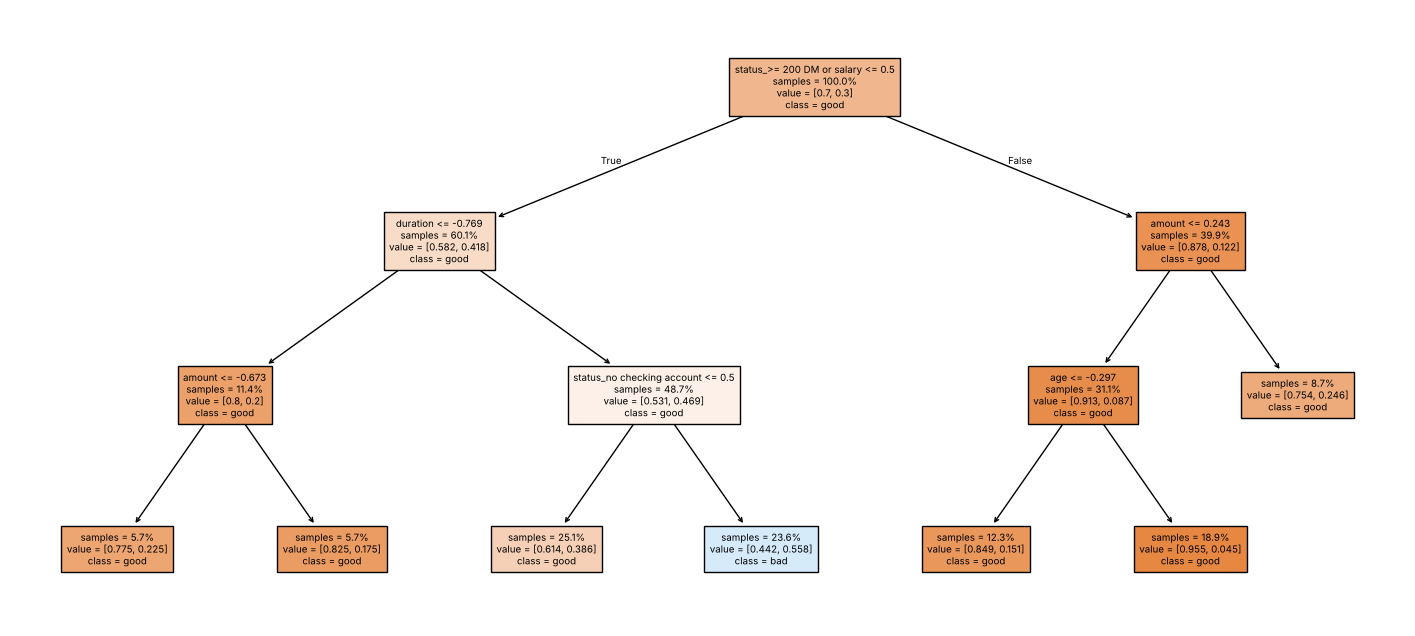

,importance
status_>= 200 DM or salary,0.620
duration,0.198
status_no checking account,0.105
amount,0.053
age,0.025
status_< 0 DM,0.000
status_0 to 200 DM,0.000
credit_history_all credits at this bank paid back duly,0.000


In [6]:
tree = model.named_steps["model"]
names = model.named_steps["preprocess"].get_feature_names_out()

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=list(names), class_names=["good", "bad"], max_depth=3,
          filled=True, impurity=False, proportion=True, fontsize=7, ax=ax)
fig.savefig(h.FIGURES / "cart_tree.png", dpi=140, bbox_inches="tight")
plt.show()

importance = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False).head(8)
importance.round(3).to_frame("importance")

### 3.5 Save the predictions and the fitted model for the comparison (D) and monitoring (E)

In [7]:
out = pd.DataFrame({"pd_pred": pd_test, "bad_credit": y_test.to_numpy()}, index=y_test.index)
out.to_csv(h.OUTPUTS / "preds_CART.csv")
joblib.dump(model, h.MODELS / "CART.joblib")
print("Saved predictions and model")

Saved predictions and model
